# Drift on NF-CICIDS2018, replayed day by day

On NF-UNSW-NB15 the binary model does not degrade between the two capture sessions (recall 0.999 on the
training day, 1.000 four weeks later): the second session contains the same attack families, made by the
same generator. A binary IDS fails on attacks it has never seen, and NF-CICIDS2018 brings a new attack
family almost every day (14 Feb - 2 Mar 2018).

Two models are replayed day by day:

- **frozen**: the Random Forest built by the DVC pipeline (`models/random_forest/model.joblib`, trained on
  NF-UNSW-NB15), deployed as is on the NF-CICIDS2018 network and never updated;
- **retrained**: retrained every night on the UNSW training data plus all previous CIC days (the labels of a
  day arrive the next day).

The replay is the DVC stage `drift@random_forest` (`src/drift.py`, settings under `drift` in `params.yaml`).
This notebook only reads its outputs in `evaluation/random_forest/drift/` and plots them. Get the data with `dvc pull` and run `dvc repro`
first.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import yaml

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = ROOT / "evaluation/random_forest/drift"

with open(ROOT / "params.yaml") as f:
    PSI_ALERT = yaml.safe_load(f)["drift"]["psi_alert"]

days = pd.read_csv(OUT / "days.csv", parse_dates=["day"])
families = pd.read_csv(OUT / "families.csv", parse_dates=["day"])
with open(OUT / "summary.json") as f:
    summary = json.load(f)

PERCENT = FuncFormatter(lambda v, _: f"{v:g} %")  # axis ticks as percentages
labels = [f"{d:%d %b}\n{a}" for d, a in zip(days["day"], days["attacks"])]
x = np.arange(len(days))
print(json.dumps(summary, indent=2))

{
  "days": 10,
  "frozen": {
    "mean_mcc": 0.0644375450278959,
    "mean_false_positive_%": 66.60125551443679
  },
  "retrained": {
    "mean_mcc": 0.17212526420064272,
    "mean_mcc_new_family_days": 0.11277358125580786,
    "mean_false_positive_%": 0.029874589567118876
  },
  "psi_vs_previous_day": {
    "new_family_days": 7,
    "alerts_on_new_family_days": 3,
    "alerts_on_control_days": 0
  }
}


## 1. Days and attack families

Flows of the sample (20 % of the dataset). 27 Feb is skipped: a few hundred flows only.

In [2]:
names = (families.groupby("day")
         .apply(lambda g: ", ".join(f"{f} ({n:,})" for f, n in zip(g["family"], g["flows"])), include_groups=False))
table = days[["day", "flows", "attack_%"]].assign(families=days["day"].map(names).fillna("no attack"))
table.assign(day=table["day"].dt.strftime("%d %b")).round(2)

,day,flows,attack_%,families
0,14 Feb,427661,26.90,"FTP brute force (77,300), SSH brute force (37,..."
1,15 Feb,333605,5.83,"DoS GoldenEye (12,209), DoS Slowloris (7,233)"
2,16 Feb,356431,11.45,"DoS Hulk (19,898), DoS SlowHTTPTest (20,907)"
3,20 Feb,365634,15.84,"DDoS LOIC-HTTP (57,903)"
4,21 Feb,543396,38.12,"DDoS HOIC (206,489), DDoS LOIC-UDP (670)"
5,22 Feb,407768,0.12,"SQL injection (80), XSS (94), web brute force ..."
6,23 Feb,386251,0.00,no attack
7,28 Feb,405310,4.14,"infiltration (16,794)"
8,01 Mar,428618,4.76,"infiltration (20,397)"
9,02 Mar,366358,11.35,"botnet (41,569)"


## 2. Detection per day

The main metric is the **MCC** (Matthews correlation coefficient). It uses the four cells of the confusion matrix:
1 = perfect, 0 = no better than chance, negative = worse. Unlike F1 it also counts the benign flows correctly let
through, and unlike accuracy it is not inflated by the large share of benign flows, so it punishes missed attacks
and false alarms alike. It depends on the share of attacks of the day (0.1 % to 38 % here): it compares two models
on the same day better than two days with each other. It is undefined on 23 Feb (no attack).
Recall and false positive rate explain the MCC.

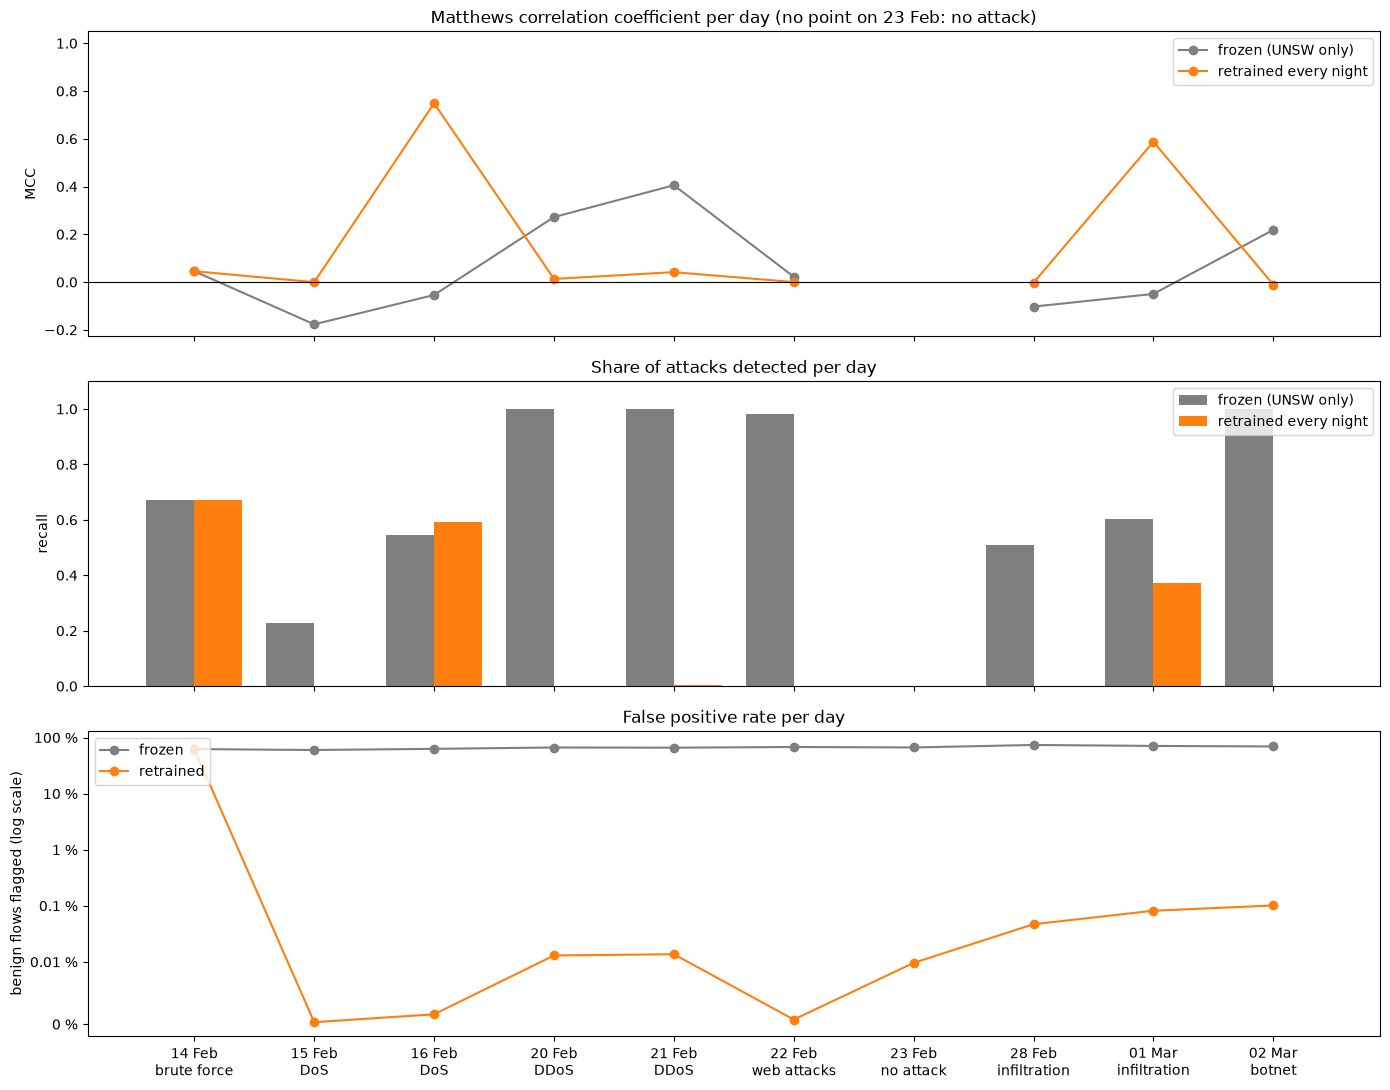

,day,attacks,flows,attack_%,frozen_recall,frozen_false_positive_%,frozen_mcc,retrained_recall,retrained_false_positive_%,retrained_mcc
0,14 Feb,brute force,427661,26.8954,0.6721,62.2908,0.0453,0.6721,62.2908,0.0453
1,15 Feb,DoS,333605,5.8279,0.2262,59.9440,-0.1770,0.0000,0.0003,-0.0004
2,16 Feb,DoS,356431,11.4482,0.5466,62.9181,-0.0541,0.5904,0.0016,0.7487
3,20 Feb,DDoS,365634,15.8363,1.0000,66.4499,0.2721,0.0007,0.0130,0.0132
4,21 Feb,DDoS,543396,38.1230,1.0000,65.9547,0.4055,0.0032,0.0137,0.0415
5,22 Feb,web attacks,407768,0.1177,0.9812,67.8861,0.0222,0.0000,0.0007,-0.0001
6,23 Feb,no attack,386251,0.0000,NaN,66.5800,NaN,NaN,0.0098,NaN
7,28 Feb,infiltration,405310,4.1435,0.5079,73.7483,-0.1028,0.0002,0.0468,-0.0027
8,01 Mar,infiltration,428618,4.7588,0.6022,70.8807,-0.0497,0.3730,0.0816,0.5876
9,02 Mar,botnet,366358,11.3466,1.0000,69.3598,0.2185,0.0000,0.1013,-0.0107


In [3]:
fig, (ax0, ax1, ax2) = plt.subplots(3, 1, figsize=(14, 11), sharex=True)
mcc_cols = ["frozen_mcc", "retrained_mcc"]
ax0.plot(x, days["frozen_mcc"], "o-", color="tab:grey", label="frozen (UNSW only)")
ax0.plot(x, days["retrained_mcc"], "o-", color="tab:orange", label="retrained every night")
ax0.axhline(0, color="black", lw=0.8)
ax0.set_ylim(min(0, days[mcc_cols].min().min()) - 0.05, 1.05)
ax0.set_ylabel("MCC")
ax0.set_title("Matthews correlation coefficient per day (no point on 23 Feb: no attack)")
ax0.legend(loc="upper right")

ax1.bar(x - 0.2, days["frozen_recall"], 0.4, label="frozen (UNSW only)", color="tab:grey")
ax1.bar(x + 0.2, days["retrained_recall"], 0.4, label="retrained every night", color="tab:orange")
ax1.set_ylim(0, 1.1)
ax1.set_ylabel("recall")
ax1.set_title("Share of attacks detected per day")
ax1.legend(loc="upper right")

ax2.plot(x, days["frozen_false_positive_%"], "o-", color="tab:grey", label="frozen")
ax2.plot(x, days["retrained_false_positive_%"], "o-", color="tab:orange", label="retrained")
ax2.set_yscale("symlog", linthresh=0.01)
ax2.yaxis.set_major_formatter(PERCENT)
ax2.set_ylabel("benign flows flagged (log scale)")
ax2.set_title("False positive rate per day")
ax2.set_xticks(x, labels)
ax2.legend(loc="upper left")
plt.tight_layout()
plt.show()

days[["day", "attacks", "flows", "attack_%", "frozen_recall", "frozen_false_positive_%", "frozen_mcc",
      "retrained_recall", "retrained_false_positive_%", "retrained_mcc"]].assign(
    day=days["day"].dt.strftime("%d %b")).round(4)

In [4]:
# Recall per attack family (the binary model never sees the family name)
families.assign(day=families["day"].dt.strftime("%d %b")).round(3)

,day,family,flows,recall_frozen,recall_retrained
0,14 Feb,FTP brute force,77300,1.000,1.000
1,14 Feb,SSH brute force,37721,0.000,0.000
2,15 Feb,DoS GoldenEye,12209,0.125,0.000
3,15 Feb,DoS Slowloris,7233,0.397,0.000
4,16 Feb,DoS Hulk,19898,0.070,0.160
5,16 Feb,DoS SlowHTTPTest,20907,1.000,1.000
6,20 Feb,DDoS LOIC-HTTP,57903,1.000,0.001
7,21 Feb,DDoS HOIC,206489,1.000,0.000
8,21 Feb,DDoS LOIC-UDP,670,1.000,1.000
9,22 Feb,SQL injection,80,1.000,0.000


## 3. Drift alerts without labels

The labels arrive late, so the monitoring job needs a signal it can compute right away: the PSI of each
feature between the traffic of the day and a reference. Two references are compared:

- the UNSW training data (what the frozen model learned);
- the previous day.

An alert is raised when the highest feature PSI exceeds 0.25. 23 Feb has no attack: an alert that day is a
false alert.

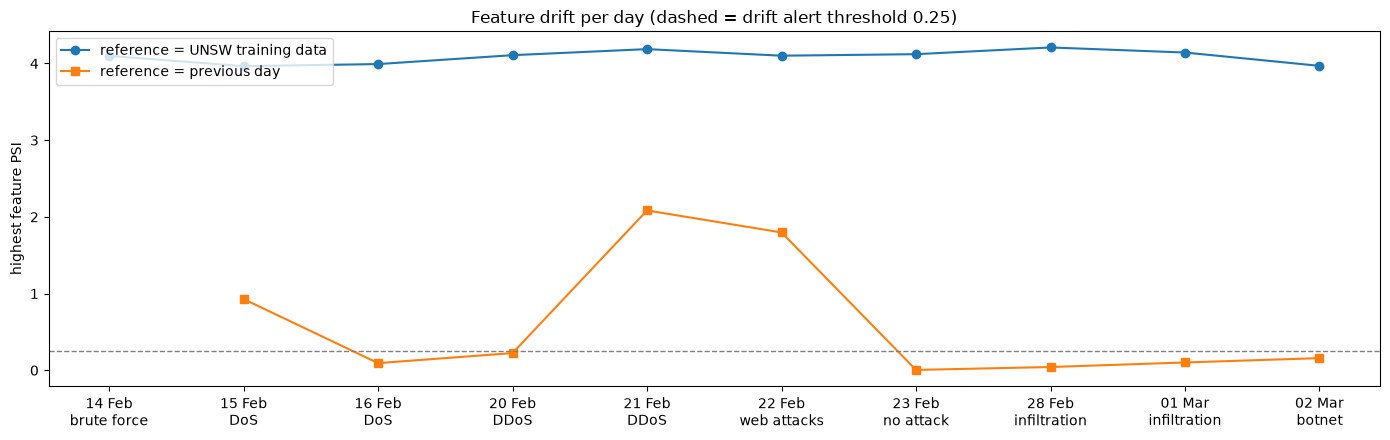

,day,new_family,psi_vs_unsw,top_feature_unsw,psi_vs_previous_day,top_feature_previous_day
0,14 Feb,True,4.099,RETRANSMITTED_OUT_PKTS,NaN,NaN
1,15 Feb,True,3.965,RETRANSMITTED_OUT_PKTS,0.928,TCP_FLAGS
2,16 Feb,True,3.992,DST_TO_SRC_SECOND_BYTES,0.093,CLIENT_TCP_FLAGS
3,20 Feb,True,4.109,RETRANSMITTED_OUT_PKTS,0.224,NUM_PKTS_UP_TO_128_BYTES
4,21 Feb,True,4.187,RETRANSMITTED_OUT_PKTS,2.084,LONGEST_FLOW_PKT
5,22 Feb,True,4.102,RETRANSMITTED_OUT_PKTS,1.797,LONGEST_FLOW_PKT
6,23 Feb,False,4.121,RETRANSMITTED_OUT_PKTS,0.004,SRC_TO_DST_AVG_THROUGHPUT
7,28 Feb,True,4.209,RETRANSMITTED_OUT_PKTS,0.042,LONGEST_FLOW_PKT
8,01 Mar,False,4.143,DST_TO_SRC_SECOND_BYTES,0.102,LONGEST_FLOW_PKT
9,02 Mar,True,3.969,RETRANSMITTED_OUT_PKTS,0.158,NUM_PKTS_UP_TO_128_BYTES


In [5]:
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(x, days["psi_vs_unsw"], "o-", label="reference = UNSW training data")
ax.plot(x, days["psi_vs_previous_day"], "s-", label="reference = previous day")
ax.axhline(PSI_ALERT, ls="--", color="grey", lw=1)
ax.set_ylabel("highest feature PSI")
ax.set_title(f"Feature drift per day (dashed = drift alert threshold {PSI_ALERT})")
ax.set_xticks(x, labels)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

days[["day", "new_family", "psi_vs_unsw", "top_feature_unsw", "psi_vs_previous_day", "top_feature_previous_day"]
     ].assign(day=days["day"].dt.strftime("%d %b")).round(3)

## What this shows

- The pipeline's model, trained on UNSW, is unusable on the CIC network: it flags 60 to 74 % of the benign flows
  every day, and its MCC stays between -0.18 and 0.41. Its high recall on some days only comes from flagging most of
  the traffic. The two networks differ so much that the feature PSI against the UNSW data is about 4 every day, the
  control day included: a model has to be trained on the network where it is deployed.
- Retrained every night on UNSW plus the previous CIC days, the model flags almost no benign flow from the second day
  on (0.0003 % to 0.1 %), but its MCC is about 0 on most days a new family appears. It only scores when an attack
  looks like one already seen or comes back: MCC 0.75 on 16 Feb (DoS SlowHTTPTest caught) and 0.59 on 1 Mar (second
  day of infiltration). Most families last one day, so it is always one day late, and it fails silently.
- Feature PSI against the previous day stays quiet on 23 Feb (0.004, no attack), but only 3 of the 7 days with a new
  family exceed 0.25 (15, 21 and 22 Feb; on 22 Feb most likely because the DDoS of the day before stopped, the web
  attacks being 0.1 % of the flows). Neither reference meets SMART objective 3 yet.